In [1]:
import glob, random, time
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [2]:
!pip install -q transformers

In [3]:
OUT = Path(glob.glob("/kaggle/input/**/tiles.csv", recursive=True)[0]).parent
print(OUT)

/kaggle/input/datasets/aaminajadoon/deepglobe-tiles/deepglobe_tiles


In [4]:
CLASS_NAMES  = ["urban", "agriculture", "rangeland", "forest", "water", "barren"]
NUM_CLASSES  = 6
IGNORE_INDEX = 255
CLASS_COLORS = np.array([[0,255,255],[255,255,0],[255,0,255],
                         [0,255,0],[0,0,255],[255,255,255]], dtype=np.uint8)
MEAN, STD, CROP = (0.485,0.456,0.406), (0.229,0.224,0.225), 512
device = "cuda" if torch.cuda.is_available() else "cpu"

def class_to_rgb(cls):
    out = np.zeros(cls.shape + (3,), dtype=np.uint8)
    for k in range(NUM_CLASSES):
        out[cls == k] = CLASS_COLORS[k]
    return out

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(42)
print("device:", device)

device: cuda


In [5]:
from transformers import SegformerForSemanticSegmentation

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b0",
    num_labels=NUM_CLASSES,
    ignore_mismatched_sizes=True,
).to(device)

params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"parameters: {params:.1f} M")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/14.4M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

SegformerForSemanticSegmentation LOAD REPORT from: nvidia/mit-b0
Key                                           | Status     | 
----------------------------------------------+------------+-
classifier.bias                               | UNEXPECTED | 
classifier.weight                             | UNEXPECTED | 
decode_head.linear_fuse.weight                | MISSING    | 
decode_head.classifier.weight                 | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.bias   | MISSING    | 
decode_head.batch_norm.weight                 | MISSING    | 
decode_head.batch_norm.running_var            | MISSING    | 
decode_head.linear_c.{0, 1, 2, 3}.proj.weight | MISSING    | 
decode_head.batch_norm.num_batches_tracked    | MISSING    | 
decode_head.classifier.bias                   | MISSING    | 
decode_head.batch_norm.bias                   | MISSING    | 
decode_head.batch_norm.running_mean           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different ta

parameters: 3.7 M


In [6]:
xt = torch.randn(2, 3, 512, 512, device=device)
model.eval()
with torch.no_grad():
    out = model(pixel_values=xt)
print("raw model output:", tuple(out.logits.shape))

logits_full = F.interpolate(out.logits, size=(512, 512), mode="bilinear", align_corners=False)
print("after upsample   :", tuple(logits_full.shape))

model.safetensors:   0%|          | 0.00/14.3M [00:00<?, ?B/s]

raw model output: (2, 6, 128, 128)
after upsample   : (2, 6, 512, 512)


In [7]:
#Transforms
train_tf = A.Compose([
    A.RandomCrop(height=CROP, width=CROP),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_tf = A.Compose([
    A.CenterCrop(height=CROP, width=CROP),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

In [8]:
#Dataset and DataLoader
class DeepGlobeTiles(Dataset):
    def __init__(self, root, split, transform):
        df = pd.read_csv(Path(root) / "tiles.csv")
        self.df = df[df.split == split].reset_index(drop=True)
        self.root, self.transform = Path(root), transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img  = cv2.cvtColor(cv2.imread(str(self.root / r.image_path)), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(self.root / r.mask_path), cv2.IMREAD_GRAYSCALE)
        out = self.transform(image=img, mask=mask)
        return out["image"], out["mask"].long()

train_ds = DeepGlobeTiles(OUT, "train", train_tf)
val_ds   = DeepGlobeTiles(OUT, "val",   val_tf)

train_dl = DataLoader(train_ds, batch_size=8, shuffle=True,  num_workers=4,
                      pin_memory=True, drop_last=True, persistent_workers=True)
val_dl   = DataLoader(val_ds,   batch_size=8, shuffle=False, num_workers=2,
                      pin_memory=True, persistent_workers=True)

print("train tiles:", len(train_ds), "| batches:", len(train_dl))
print("val tiles  :", len(val_ds),   "| batches:", len(val_dl))

train tiles: 8992 | batches: 1124
val tiles  : 1920 | batches: 240


In [9]:
#Loss
class DiceLoss(nn.Module):
    def __init__(self, num_classes=6, ignore_index=255, eps=1e-6):
        super().__init__()
        self.n, self.ignore, self.eps = num_classes, ignore_index, eps
    def forward(self, logits, target):
        probs = logits.float().softmax(dim=1)
        valid = (target != self.ignore)
        safe  = target.masked_fill(~valid, 0)
        onehot = F.one_hot(safe, self.n).permute(0, 3, 1, 2).float()
        valid = valid.unsqueeze(1)
        probs, onehot = probs * valid, onehot * valid
        inter = (probs * onehot).sum(dim=(0, 2, 3))
        total = probs.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))
        dice  = (2 * inter + self.eps) / (total + self.eps)
        present = onehot.sum(dim=(0, 2, 3)) > 0
        return 1 - dice[present].mean()

class CEDiceLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, ignore_index=IGNORE_INDEX)
        self.dice = DiceLoss()
    def forward(self, logits, target):
        logits = logits.float()
        return self.ce(logits, target) + self.dice(logits, target)

criterion = CEDiceLoss()

In [10]:
#Metric
class SegMetrics:
    def __init__(self, num_classes=NUM_CLASSES, ignore_index=IGNORE_INDEX):
        self.n, self.ignore = num_classes, ignore_index
        self.reset()
    def reset(self):
        self.cm = torch.zeros(self.n, self.n, dtype=torch.long)
    @torch.no_grad()
    def update(self, preds, targets):
        preds, targets = preds.flatten().long(), targets.flatten().long()
        keep = targets != self.ignore
        idx = targets[keep] * self.n + preds[keep]
        self.cm += torch.bincount(idx, minlength=self.n * self.n).reshape(self.n, self.n).cpu()
    def compute(self):
        cm = self.cm.double(); tp = cm.diag()
        fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
        iou = tp / (tp + fp + fn)
        return {"iou_per_class": iou, "mIoU": torch.nanmean(iou).item(),
                "pixel_acc": (tp.sum() / cm.sum()).item()}

In [11]:
#Test: run one real batch through the model, loss, and metric together
x, y = next(iter(train_dl))
x, y = x.to(device), y.to(device)

model.train()
out = model(pixel_values=x)
logits = F.interpolate(out.logits, size=y.shape[-2:], mode="bilinear", align_corners=False)

loss = criterion(logits, y)
print("logits:", tuple(logits.shape), "| loss:", loss.item())

m = SegMetrics()
m.update(logits.argmax(dim=1), y)
print("mIoU on one untrained batch:", round(m.compute()["mIoU"], 4))

logits: (8, 6, 512, 512) | loss: 2.730968475341797
mIoU on one untrained batch: 0.0367


In [12]:
encoder_params = model.segformer.encoder.parameters()
head_params    = model.decode_head.parameters()

optimizer = torch.optim.AdamW([
    {"params": encoder_params, "lr": 6e-5},   # gentle: it's already good
    {"params": head_params,    "lr": 6e-4},   # 10x faster: it's starting from scratch
], weight_decay=1e-4)

In [13]:
#Training loop with discriminative learning rates
import time
import torch
from torch.amp import autocast, GradScaler
from tqdm.auto import tqdm

torch.backends.cudnn.benchmark = True

# ---------------- config ----------------
NUM_EPOCHS = 12
BATCH = 8
ENC_LR, HEAD_LR = 6e-5, 6e-4
WEIGHT_DECAY = 1e-4
BEST_PATH, LAST_PATH = "best_segformer.pth", "last_segformer.pth"

# ---------------- model, optimizer, loss, schedule ----------------
seed_everything(42)

optimizer = torch.optim.AdamW([
    {"params": model.segformer.encoder.parameters(), "lr": ENC_LR},
    {"params": model.decode_head.parameters(),        "lr": HEAD_LR},
], weight_decay=WEIGHT_DECAY)

scaler, criterion = GradScaler("cuda"), CEDiceLoss()

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=[ENC_LR, HEAD_LR],          # one peak LR per parameter group, same order as above
    steps_per_epoch=len(train_dl),
    epochs=NUM_EPOCHS,
    pct_start=0.2,
)

print(f"params: {sum(p.numel() for p in model.parameters())/1e6:.1f} M | "
      f"{len(train_dl)} train batches/epoch | {NUM_EPOCHS} epochs")

history = {"train_loss": [], "val_loss": [], "val_mIoU": [], "val_pixel_acc": []}
best_miou, best_iou_per_class = 0.0, None

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()

    # ----- train -----
    model.train(); run = 0.0
    for x, y in tqdm(train_dl, desc=f"Epoch {epoch:02d} [train]", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast("cuda", dtype=torch.float16):
            out = model(pixel_values=x)
            logits = F.interpolate(out.logits, size=y.shape[-2:], mode="bilinear", align_corners=False)
        loss = criterion(logits, y)                    # 32-bit loss math
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        scheduler.step()
        run += loss.item()
    train_loss = run / len(train_dl)

    # ----- validate -----
    model.eval(); run = 0.0; metrics = SegMetrics()
    with torch.no_grad():
        for x, y in tqdm(val_dl, desc=f"Epoch {epoch:02d} [val]", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with autocast("cuda", dtype=torch.float16):
                out = model(pixel_values=x)
                logits = F.interpolate(out.logits, size=y.shape[-2:], mode="bilinear", align_corners=False)
            run += criterion(logits, y).item()
            metrics.update(logits.argmax(dim=1), y)
    val_loss, res = run / len(val_dl), metrics.compute()

    # ----- bookkeeping -----
    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
    history["val_mIoU"].append(res["mIoU"]);  history["val_pixel_acc"].append(res["pixel_acc"])

    note = ""
    if res["mIoU"] > best_miou:
        best_miou, best_iou_per_class = res["mIoU"], res["iou_per_class"].clone()
        torch.save({"model": model.state_dict(), "epoch": epoch, "mIoU": best_miou}, BEST_PATH)
        note = "  <- best, saved"
    torch.save({"model": model.state_dict(), "epoch": epoch, "history": history}, LAST_PATH)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} ({time.time()-t0:.0f}s) | train {train_loss:.4f} | "
          f"val {val_loss:.4f} | mIoU {res['mIoU']:.4f} | acc {res['pixel_acc']:.4f}{note}")

params: 3.7 M | 1124 train batches/epoch | 12 epochs


Epoch 01 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

Epoch 01 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 01/12 (246s) | train 1.4346 | val 0.9020 | mIoU 0.6333 | acc 0.8493  <- best, saved


Epoch 02 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

...

Epoch 11 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 11/12 (229s) | train 0.5430 | val 0.6498 | mIoU 0.7336 | acc 0.8932


Epoch 12 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

Epoch 12 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 12/12 (228s) | train 0.5318 | val 0.6466 | mIoU 0.7365 | acc 0.8936


In [14]:
import json
json.dump({"history": history,
           "best_mIoU": best_miou,
           "best_iou_per_class": best_iou_per_class.tolist(),
           "classes": CLASS_NAMES},
          open("segformer_results.json", "w"))

In [15]:
@torch.no_grad()
def full_report(model, loader):
    model.eval(); m = SegMetrics()
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with autocast("cuda", dtype=torch.float16):
            out = model(pixel_values=x)
            logits = F.interpolate(out.logits, size=y.shape[-2:], mode="bilinear", align_corners=False)
        m.update(logits.argmax(1), y)
    cm = m.cm.double()
    tp = cm.diag(); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    table = pd.DataFrame({
        "IoU":       (tp / (tp + fp + fn)).numpy(),
        "precision": (tp / (tp + fp)).numpy(),
        "recall":    (tp / (tp + fn)).numpy(),
        "share_%":   (100 * cm.sum(1) / cm.sum()).numpy(),
    }, index=CLASS_NAMES)
    return cm, table

ck = torch.load(BEST_PATH, map_location=device)
model.load_state_dict(ck["model"])
cm, table = full_report(model, val_dl)
print(table.round(3))
print(f"\nmIoU: {table.IoU.mean():.4f}")

               IoU  precision  recall  share_%
urban        0.782      0.854   0.902    9.965
agriculture  0.892      0.946   0.939   60.125
rangeland    0.458      0.689   0.576    7.756
forest       0.811      0.868   0.925   10.749
water        0.818      0.900   0.900    3.153
barren       0.668      0.781   0.823    8.253

mIoU: 0.7381


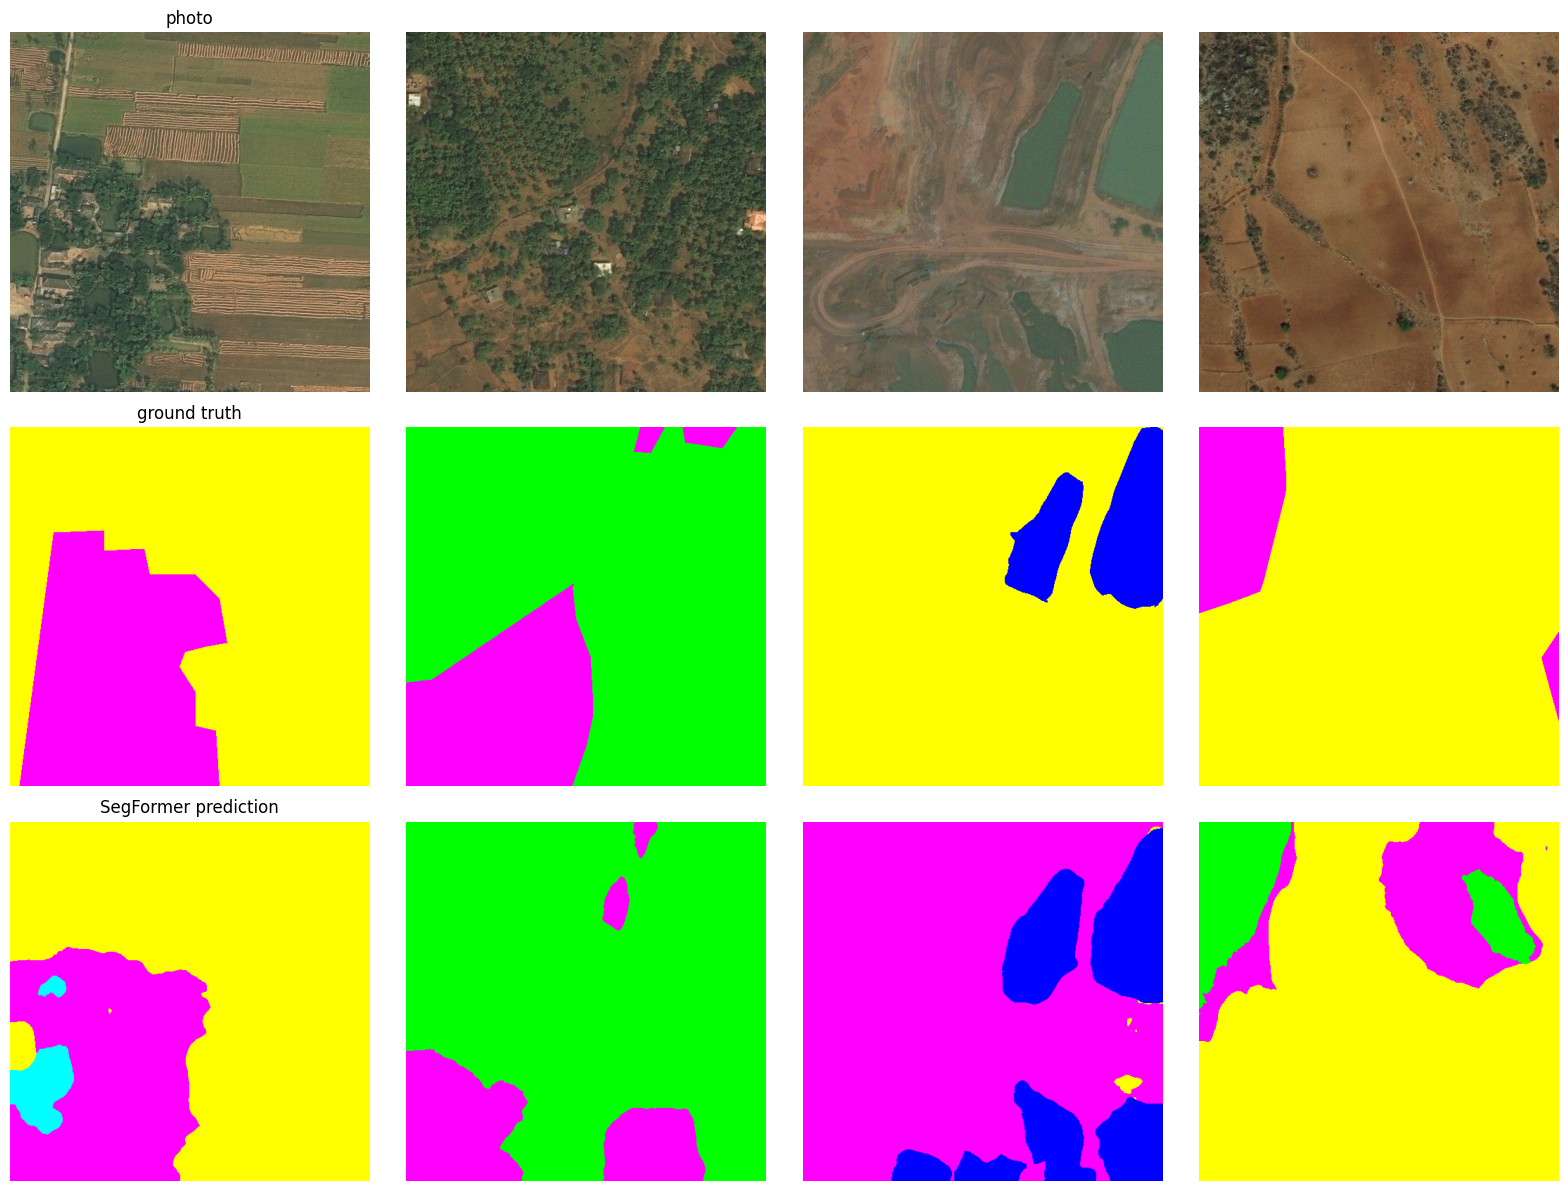

In [16]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device)["model"])
model.eval()
mean = torch.tensor(MEAN).view(3, 1, 1); std = torch.tensor(STD).view(3, 1, 1)

idx = [0, 500, 1000, 1500]                       # spread across different source images
xb = torch.stack([val_ds[i][0] for i in idx])
yb = torch.stack([val_ds[i][1] for i in idx])

with torch.no_grad(), autocast("cuda", dtype=torch.float16):
    out = model(pixel_values=xb.to(device))
    logits = F.interpolate(out.logits, size=yb.shape[-2:], mode="bilinear", align_corners=False)
pred = logits.argmax(1).cpu()

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for k in range(4):
    axes[0, k].imshow((xb[k] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
    axes[1, k].imshow(class_to_rgb(yb[k].numpy()))
    axes[2, k].imshow(class_to_rgb(pred[k].numpy()))
    for r in range(3): axes[r, k].axis("off")
axes[0, 0].set_title("photo"); axes[1, 0].set_title("ground truth"); axes[2, 0].set_title("SegFormer prediction")
plt.tight_layout(); plt.savefig("segformer_predictions.png", dpi=120)
plt.show()

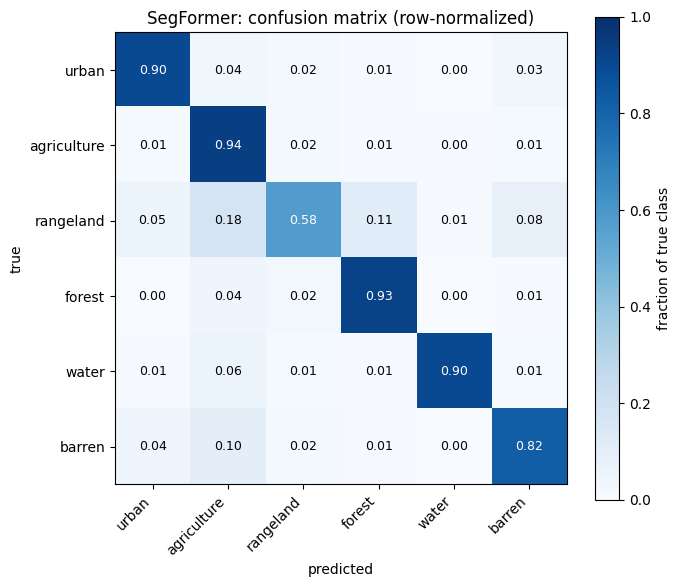

In [17]:
row_norm = (cm / cm.sum(1, keepdim=True)).numpy()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(row_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(6)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(6)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("SegFormer: confusion matrix (row-normalized)")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{row_norm[i,j]:.2f}", ha="center", va="center",
                color="white" if row_norm[i,j] > 0.5 else "black", fontsize=9)
plt.colorbar(im, label="fraction of true class")
plt.tight_layout(); plt.savefig("segformer_confusion.png", dpi=120)
plt.show()

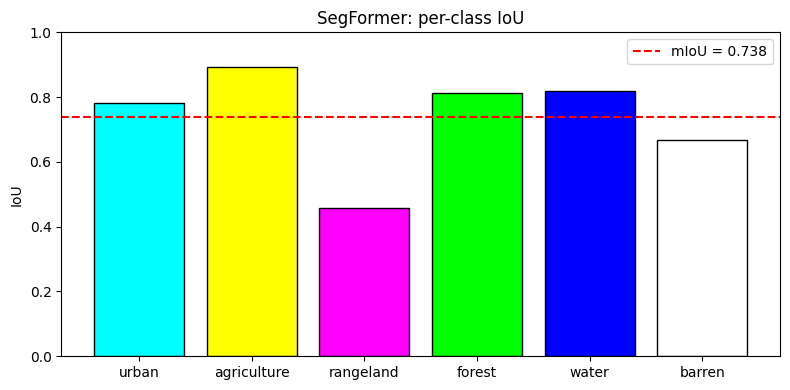

In [18]:
plt.figure(figsize=(8, 4))
bars = plt.bar(CLASS_NAMES, table["IoU"], color=CLASS_COLORS / 255.0, edgecolor="k")
plt.axhline(table["IoU"].mean(), color="red", linestyle="--", label=f"mIoU = {table['IoU'].mean():.3f}")
plt.ylabel("IoU"); plt.title("SegFormer: per-class IoU"); plt.ylim(0, 1); plt.legend()
plt.tight_layout(); plt.savefig("segformer_per_class_iou.png", dpi=120)
plt.show()

In [19]:
import os

def model_facts(model, path):
    size_mb = os.path.getsize(path) / 1e6
    x = torch.randn(8, 3, 512, 512, device=device)
    model.eval()
    with torch.no_grad(), autocast("cuda", dtype=torch.float16):
        for _ in range(3):
            out = model(pixel_values=x)
            F.interpolate(out.logits, size=(512,512), mode="bilinear", align_corners=False)
        torch.cuda.synchronize(); t0 = time.time()
        for _ in range(10):
            out = model(pixel_values=x)
            F.interpolate(out.logits, size=(512,512), mode="bilinear", align_corners=False)
        torch.cuda.synchronize()
    ms = (time.time() - t0) / 10 * 1000
    return round(size_mb, 1), round(ms, 1)

size_mb, ms = model_facts(model, "best_segformer.pth")
print(f"SegFormer | weights: {size_mb} MB | inference: {ms} ms per batch of 8")

SegFormer | weights: 15.0 MB | inference: 62.5 ms per batch of 8


In [20]:
test_ds = DeepGlobeTiles(OUT, "test", val_tf)     # same center-crop transform as validation
test_dl = DataLoader(test_ds, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
print("test tiles:", len(test_ds))

cm, table = full_report(model, test_dl)
print(table.round(4))
print(f"\nSegFormer TEST mIoU: {table.IoU.mean():.4f}")

test tiles: 1936
                IoU  precision  recall  share_%
urban        0.7854     0.8639  0.8963  10.4839
agriculture  0.8672     0.9439  0.9143  59.3997
rangeland    0.4383     0.5930  0.6270   8.5635
forest       0.7386     0.8262  0.8745   9.5718
water        0.7317     0.8946  0.8008   1.6399
barren       0.6994     0.8008  0.8467  10.3412

SegFormer TEST mIoU: 0.7101


In [21]:
import os, json, zipfile
import pandas as pd
from IPython.display import FileLink, display

WORK = "/kaggle/working"
os.chdir(WORK)

# ---------- 1. save anything still only in memory ----------

# test-set per-class table (from your last full_report call on test_dl)
table.round(4).to_csv(f"{WORK}/segformer_per_class_test.csv")

# results summary (history, best mIoU, per-class IoU from validation)
json.dump({
    "history": history,
    "best_val_mIoU": best_miou,
    "best_iou_per_class_val": best_iou_per_class.tolist(),
    "classes": CLASS_NAMES,
}, open(f"{WORK}/segformer_results.json", "w"))

# model facts (params, weights size, inference speed)
pd.DataFrame([{
    "Model": "SegFormer (mit-b0)",
    "Parameters (M)": round(sum(p.numel() for p in model.parameters()) / 1e6, 1),
    "Weights file (MB)": size_mb,
    "Inference ms per batch of 8": ms,
}]).to_csv(f"{WORK}/segformer_model_facts.csv", index=False)

# a combined comparison table across all three models, using the numbers we've gathered
comparison = pd.DataFrame([
    {"Model": "Scratch UNet",              "Params (M)": 7.8,  "Weights (MB)": 31.1, "Inference (ms)": 94.7,
     "Test mIoU": 0.5698, "Test pixel acc": 0.8050},
    {"Model": "Pretrained ResNet34 UNet",  "Params (M)": 24.4, "Weights (MB)": 97.9, "Inference (ms)": 67.0,
     "Test mIoU": 0.6913, "Test pixel acc": 0.8642},
    {"Model": "SegFormer (mit-b0)",        "Params (M)": round(sum(p.numel() for p in model.parameters())/1e6, 1),
     "Weights (MB)": size_mb, "Inference (ms)": ms,
     "Test mIoU": round(table.IoU.mean(), 4), "Test pixel acc": None},   # fill pixel acc if you have it
])
comparison.to_csv(f"{WORK}/three_model_comparison.csv", index=False)
print(comparison.to_string(index=False))

# ---------- 2. package everything into one zip ----------

files_to_pack = [
    "best_segformer.pth",
    "last_segformer.pth",
    "segformer_results.json",
    "segformer_per_class_test.csv",
    "segformer_model_facts.csv",
    "three_model_comparison.csv",
    "segformer_predictions.png",
    "segformer_confusion.png",
    "segformer_per_class_iou.png",
]

zip_name = "segformer_results.zip"
with zipfile.ZipFile(os.path.join(WORK, zip_name), "w", zipfile.ZIP_DEFLATED) as z:
    for name in files_to_pack:
        path = os.path.join(WORK, name)
        if os.path.exists(path):
            z.write(path, arcname=name)
        else:
            print("skipped, not found:", name)

print("\nzip size:", round(os.path.getsize(os.path.join(WORK, zip_name)) / 1e6, 1), "MB")
display(FileLink(zip_name))

                   Model  Params (M)  Weights (MB)  Inference (ms)  Test mIoU  Test pixel acc
            Scratch UNet         7.8          31.1            94.7     0.5698          0.8050
Pretrained ResNet34 UNet        24.4          97.9            67.0     0.6913          0.8642
      SegFormer (mit-b0)         3.7          15.0            62.5     0.7101             NaN

zip size: 29.2 MB


/kaggle/working/segformer_results.zip

In [22]:
test_pixel_acc = (cm.diag().sum() / cm.sum()).item()
print(f"SegFormer TEST pixel accuracy: {test_pixel_acc:.4f}")

SegFormer TEST pixel accuracy: 0.8751


In [23]:
comparison.loc[comparison["Model"] == "SegFormer (mit-b0)", "Test pixel acc"] = test_pixel_acc
comparison.to_csv(f"{WORK}/three_model_comparison.csv", index=False)
print(comparison.to_string(index=False))

                   Model  Params (M)  Weights (MB)  Inference (ms)  Test mIoU  Test pixel acc
            Scratch UNet         7.8          31.1            94.7     0.5698        0.805000
Pretrained ResNet34 UNet        24.4          97.9            67.0     0.6913        0.864200
      SegFormer (mit-b0)         3.7          15.0            62.5     0.7101        0.875148
